# Module 12 — Hypothesis Testing and Experiments

This notebook is the runnable companion to the concept guide: read [README.md](README.md) first,
or keep it open alongside. Every section below mirrors a numbered section of the guide. We test a
coin exactly and approximately, watch p-values come out uniform under the null, draw power curves and
check them by simulation, build Welch's and the paired t-test from scratch, do a chi-square test by hand,
run a permutation test on skewed revenue data, verify that confidence intervals and tests are the same
thing, implement Bonferroni, Holm and Benjamini–Hochberg and measure what they control, see what
randomisation and blocking buy in an experiment, quantify how peeking inflates false positives, and
finally compare two classifiers properly with McNemar's test and a corrected cross-validation test.

Everything is plain NumPy first; `scipy.stats` and scikit-learn appear afterwards to confirm the hand
computation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb
from scipy import stats
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)

## 1. The logic of a test: is the coin fair after 60 heads in 100 flips?

$H_0: \theta = 0.5$ against $H_1: \theta \ne 0.5$, test statistic $X$ = number of heads. Under $H_0$,
$X \sim \text{Binomial}(100, 0.5)$, so the two-sided p-value is the probability of a count at least as far
from 50 as the observed 60, computed *assuming the coin is fair*:

$$p = P_{H_0}(X \ge 60) + P_{H_0}(X \le 40) = 2\sum_{k=60}^{100}\binom{100}{k}2^{-100}.$$

We compute it exactly from the PMF, then with the normal approximation (with and without the continuity
correction), and finally we find the exact level-0.05 rejection region of this discrete test.

P(X >= 60 | fair) = 0.0284   two-sided exact p-value = 0.0569
scipy.stats.binomtest : 0.0569

normal approximation: z = 2.00 -> p = 0.0455
with continuity correction: z = 1.90 -> p = 0.0574   (exact: 0.0569)
reject if |X - 50| >=  8:  size = 0.1332
reject if |X - 50| >=  9:  size = 0.0886
reject if |X - 50| >= 10:  size = 0.0569
reject if |X - 50| >= 11:  size = 0.0352  <- first region with size <= 0.05
reject if |X - 50| >= 12:  size = 0.0210


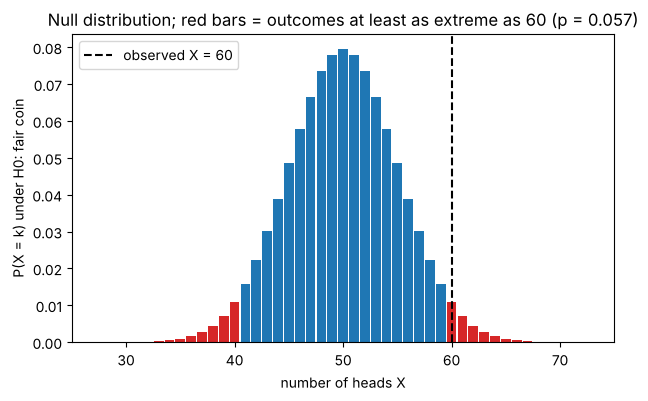

In [2]:
n, k_obs, theta0 = 100, 60, 0.5
ks = np.arange(n + 1)
pmf0 = np.array([comb(n, k) * theta0**k * (1 - theta0)**(n - k) for k in ks])   # null PMF, by hand

p_upper = pmf0[ks >= k_obs].sum()
p_lower = pmf0[ks <= n - k_obs].sum()           # mirror-image tail (the binomial(100, .5) is symmetric)
p_exact = p_upper + p_lower
print(f"P(X >= 60 | fair) = {p_upper:.4f}   two-sided exact p-value = {p_exact:.4f}")
print(f"scipy.stats.binomtest : {stats.binomtest(k_obs, n, theta0).pvalue:.4f}")

mu, sd = n * theta0, np.sqrt(n * theta0 * (1 - theta0))
z_plain = (k_obs - mu) / sd
z_cc = (abs(k_obs - mu) - 0.5) / sd                              # continuity correction
print(f"\nnormal approximation: z = {z_plain:.2f} -> p = {2 * stats.norm.sf(abs(z_plain)):.4f}")
print(f"with continuity correction: z = {z_cc:.2f} -> p = {2 * stats.norm.sf(z_cc):.4f}   (exact: {p_exact:.4f})")

# the exact level-0.05 rejection region: the smallest c such that P(|X - 50| >= c) <= 0.05
for c in range(8, 13):
    size = pmf0[np.abs(ks - mu) >= c].sum()
    flag = "  <- first region with size <= 0.05" if size <= 0.05 and pmf0[np.abs(ks - mu) >= c - 1].sum() > 0.05 else ""
    print(f"reject if |X - 50| >= {c:2d}:  size = {size:.4f}{flag}")

colors = np.where(np.abs(ks - mu) >= k_obs - mu, "C3", "C0")
plt.bar(ks, pmf0, color=colors, width=0.9)
plt.axvline(k_obs, color="k", ls="--", label="observed X = 60")
plt.xlim(25, 75); plt.xlabel("number of heads X"); plt.ylabel("P(X = k) under H0: fair coin")
plt.title("Null distribution; red bars = outcomes at least as extreme as 60 (p = 0.057)")
plt.legend(); plt.show()

Notice three things. The exact two-sided p-value is $0.057$: a fair coin produces a split at least this
lopsided about once in 18 blocks of 100 flips, so at $\alpha = 0.05$ we do **not** reject. The crude normal
approximation says $0.046$ and *would* reject — approximations matter exactly at the boundary, and the
continuity correction repairs most of the damage. And because $X$ is discrete, no region has size exactly
$0.05$: the level-0.05 test is "reject if $X \le 39$ or $X \ge 61$", whose true size is only $0.035$.

### p-values are uniform under the null

If $H_0$ is true and the statistic is continuous, the p-value is $\text{Uniform}(0, 1)$ — so exactly a fraction
$\alpha$ of true nulls are rejected. Under $H_1$ the p-values pile up near 0; the mass below $\alpha$ is the power.
We run 20,000 Welch t-tests on two samples of 20 drawn from the *same* normal distribution, then 20,000
more where the second sample is shifted by half a standard deviation.

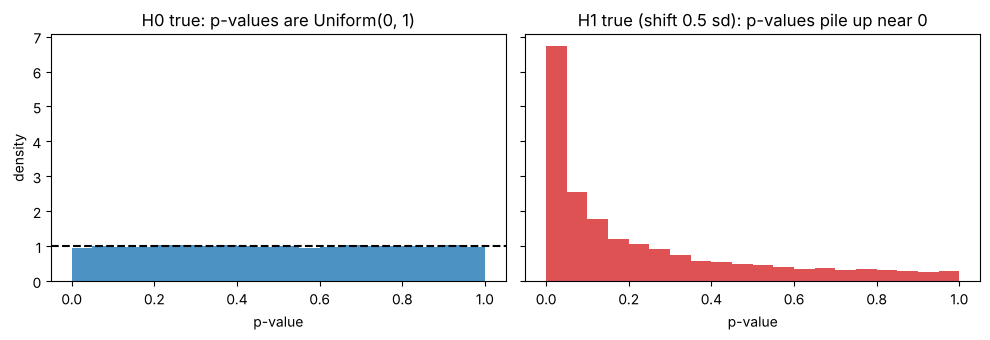

alpha = 0.01:  fraction rejected under H0 = 0.0097   under H1 = 0.1436
alpha = 0.05:  fraction rejected under H0 = 0.0477   under H1 = 0.3363
alpha = 0.10:  fraction rejected under H0 = 0.0983   under H1 = 0.4636


In [3]:
n_rep, n_s = 20_000, 20
x = rng.normal(0.0, 1.0, size=(n_rep, n_s))
y_null = rng.normal(0.0, 1.0, size=(n_rep, n_s))
y_alt = rng.normal(0.5, 1.0, size=(n_rep, n_s))
p_null = stats.ttest_ind(x, y_null, axis=1, equal_var=False).pvalue
p_alt = stats.ttest_ind(x, y_alt, axis=1, equal_var=False).pvalue

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
ax1.hist(p_null, bins=20, range=(0, 1), density=True, alpha=0.8); ax1.axhline(1, color="k", ls="--")
ax1.set_title("H0 true: p-values are Uniform(0, 1)"); ax1.set_xlabel("p-value"); ax1.set_ylabel("density")
ax2.hist(p_alt, bins=20, range=(0, 1), density=True, alpha=0.8, color="C3")
ax2.set_title("H1 true (shift 0.5 sd): p-values pile up near 0"); ax2.set_xlabel("p-value")
plt.tight_layout(); plt.show()

for a in (0.01, 0.05, 0.10):
    print(f"alpha = {a:.2f}:  fraction rejected under H0 = {(p_null <= a).mean():.4f}   under H1 = {(p_alt <= a).mean():.4f}")

Under $H_0$ the histogram is flat and the fraction of p-values below $0.05$ is $0.05$ — the false-alarm rate is
built into the procedure, whatever the data look like. Under $H_1$ the fraction below $0.05$ is the power,
here only about $0.34$: with 20 observations per group a half-standard-deviation effect is missed two times
in three. That number is the subject of the next section.

**Try it yourself:** change the shift `0.5` to `1.0` and the group size `n_s` to 40 — which change raises the
power more?

## 2. Errors and power

For the two-sample z-test with known $\sigma$, $n$ per arm and a two-sided level $\alpha$, the difference of
means has standard error $\sigma\sqrt{2/n}$ and

$$1 - \beta = \Phi\!\left(\frac{\delta}{\sigma\sqrt{2/n}} - z_{1-\alpha/2}\right) + \Phi\!\left(-\frac{\delta}{\sigma\sqrt{2/n}} - z_{1-\alpha/2}\right),
\qquad n_{\text{per arm}} = \frac{2(z_{1-\alpha/2} + z_{1-\beta})^2\sigma^2}{\delta^2}.$$

We implement both, draw power against $n$ for three effect sizes, and check the curve by simulating the
test thousands of times.

n =  25 per arm: analytic power = 0.293
n =  50 per arm: analytic power = 0.516
n = 100 per arm: analytic power = 0.807
n = 200 per arm: analytic power = 0.979

required n per arm for 80% power: 99   (formula gives 98.1)
minimum detectable effect at n = 50, 80% power: 5.60 minutes


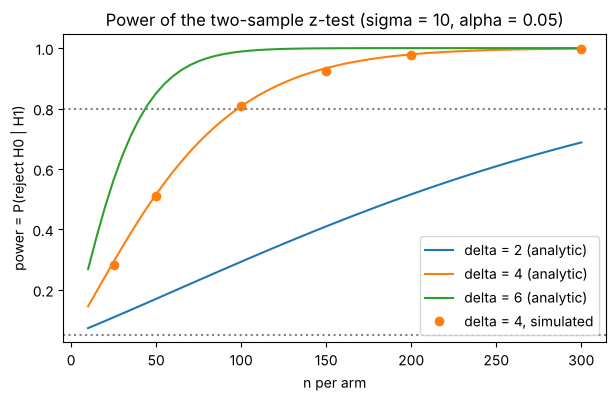

In [4]:
def power_two_sample_z(delta, sigma, n, alpha=0.05):
    se = sigma * np.sqrt(2.0 / n)
    zc = stats.norm.ppf(1 - alpha / 2)
    return stats.norm.cdf(-zc - delta / se) + stats.norm.sf(zc - delta / se)

def n_per_arm(delta, sigma, power=0.8, alpha=0.05):
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return int(np.ceil(2 * (za + zb)**2 * sigma**2 / delta**2))

def mde(sigma, n, power=0.8, alpha=0.05):
    return (stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)) * sigma * np.sqrt(2.0 / n)

sigma, delta = 10.0, 4.0
for n in (25, 50, 100, 200):
    print(f"n = {n:3d} per arm: analytic power = {power_two_sample_z(delta, sigma, n):.3f}")
print(f"\nrequired n per arm for 80% power: {n_per_arm(delta, sigma)}   (formula gives {2 * (1.96 + 0.8416)**2 * sigma**2 / delta**2:.1f})")
print(f"minimum detectable effect at n = 50, 80% power: {mde(sigma, 50):.2f} minutes")

# Monte Carlo check: simulate the experiment many times and count rejections
def simulated_power(delta, sigma, n, reps=5_000, alpha=0.05):
    a = rng.normal(0.0, sigma, size=(reps, n)); b = rng.normal(delta, sigma, size=(reps, n))
    z = (b.mean(axis=1) - a.mean(axis=1)) / (sigma * np.sqrt(2.0 / n))
    return (np.abs(z) > stats.norm.ppf(1 - alpha / 2)).mean()

ns = np.arange(10, 301, 5)
for d, c in zip((2.0, 4.0, 6.0), ("C0", "C1", "C2")):
    plt.plot(ns, power_two_sample_z(d, sigma, ns), color=c, label=f"delta = {d:.0f} (analytic)")
sim_ns = np.array([25, 50, 100, 150, 200, 300])
plt.plot(sim_ns, [simulated_power(4.0, sigma, n) for n in sim_ns], "o", color="C1", label="delta = 4, simulated")
plt.axhline(0.8, color="gray", ls=":"); plt.axhline(0.05, color="gray", ls=":")
plt.xlabel("n per arm"); plt.ylabel("power = P(reject H0 | H1)")
plt.title("Power of the two-sample z-test (sigma = 10, alpha = 0.05)")
plt.legend(); plt.show()

The simulated points fall on the analytic curve. Read the plot the way an experimenter does: with
$n = 50$ a 4-minute effect is caught only half the time, and halving the effect to 2 minutes drops the power
at $n = 50$ to $0.17$ — power grows with $\sqrt n$, so a half-size effect needs *four times* the data. The
dotted line at $0.05$ is where every curve starts: at $\delta = 0$ the "power" is just the false-positive rate.

**Try it yourself:** call `n_per_arm(2.0, 10.0)` and `n_per_arm(4.0, 10.0, power=0.9)` — what do halving the
effect and raising the power from 80% to 90% each cost in sample size?

## 3. Welch's t-test from scratch, and why pairing increases power

$$t = \frac{\bar x_1 - \bar x_2}{\sqrt{s_1^2/n_1 + s_2^2/n_2}}, \qquad
\nu = \frac{(s_1^2/n_1 + s_2^2/n_2)^2}{\dfrac{(s_1^2/n_1)^2}{n_1-1} + \dfrac{(s_2^2/n_2)^2}{n_2-1}}.$$

We apply it to the cycle-time data of the guide (old process $n_1 = 8$, new process $n_2 = 6$), report
Cohen's $d$ and a 95% confidence interval, and compare with `scipy.stats.ttest_ind(..., equal_var=False)`.
Then the paired design: six machines before and after a change, analysed paired and (wrongly) unpaired.

In [5]:
def welch_t(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    n1, n2 = len(x), len(y)
    v1, v2 = x.var(ddof=1) / n1, y.var(ddof=1) / n2
    t = (x.mean() - y.mean()) / np.sqrt(v1 + v2)
    df = (v1 + v2)**2 / (v1**2 / (n1 - 1) + v2**2 / (n2 - 1))
    p = 2 * stats.t.sf(abs(t), df)
    return t, df, p

old = np.array([52., 48, 55, 50, 53, 49, 51, 54])
new = np.array([47., 50, 44, 49, 46, 48])
t, df, p = welch_t(old, new)
print(f"means {old.mean():.2f} vs {new.mean():.2f};  sample variances {old.var(ddof=1):.3f}, {new.var(ddof=1):.3f}")
print(f"Welch by hand : t = {t:.4f}, df = {df:.3f}, p = {p:.5f}")
res = stats.ttest_ind(old, new, equal_var=False)
print(f"scipy         : t = {res.statistic:.4f}, df = {res.df:.3f}, p = {res.pvalue:.5f}")
res_pooled = stats.ttest_ind(old, new, equal_var=True)
print(f"Student pooled: t = {res_pooled.statistic:.4f}, df = {res_pooled.df:.0f}, p = {res_pooled.pvalue:.5f}")

se = np.sqrt(old.var(ddof=1) / len(old) + new.var(ddof=1) / len(new))
tcrit = stats.t.ppf(0.975, df)
diff = old.mean() - new.mean()
s_pooled = np.sqrt(((len(old) - 1) * old.var(ddof=1) + (len(new) - 1) * new.var(ddof=1)) / (len(old) + len(new) - 2))
print(f"\ndifference {diff:.2f} min, 95% CI [{diff - tcrit * se:.2f}, {diff + tcrit * se:.2f}], Cohen's d = {diff / s_pooled:.2f}")

# paired: six machines before/after
before = np.array([31.0, 28.5, 35.2, 30.1, 27.8, 33.4])
after = np.array([29.1, 27.9, 33.0, 29.6, 27.0, 31.5])
d = before - after
t_pair = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
p_pair = 2 * stats.t.sf(abs(t_pair), len(d) - 1)
print(f"\npaired differences {d}: mean {d.mean():.3f}, sd {d.std(ddof=1):.3f}")
print(f"paired t by hand: t = {t_pair:.3f}, df = {len(d) - 1}, p = {p_pair:.4f}    scipy ttest_rel: p = {stats.ttest_rel(before, after).pvalue:.4f}")
print(f"the SAME numbers analysed unpaired (Welch): p = {welch_t(before, after)[2]:.4f}   (before/after correlation = {np.corrcoef(before, after)[0, 1]:.3f})")

means 51.50 vs 47.33;  sample variances 6.000, 4.667
Welch by hand : t = 3.3710, df = 11.593, p = 0.00582
scipy         : t = 3.3710, df = 11.593, p = 0.00582
Student pooled: t = 3.3065, df = 12, p = 0.00626

difference 4.17 min, 95% CI [1.46, 6.87], Cohen's d = 1.79

paired differences [1.9 0.6 2.2 0.5 0.8 1.9]: mean 1.317, sd 0.763
paired t by hand: t = 4.229, df = 5, p = 0.0083    scipy ttest_rel: p = 0.0083
the SAME numbers analysed unpaired (Welch): p = 0.3958   (before/after correlation = 0.984)


Hand computation and scipy agree to every digit, and Student's pooled test is close here because the two
variances happen to be similar. The paired example is the dramatic one: $p = 0.008$ paired, $p = 0.40$
unpaired, from the same twelve numbers. The machines differ from each other by about 2.9 minutes while the
change moves each machine by about 1.3; pairing subtracts the machine effect
($\operatorname{Var}(\bar x - \bar y) = (\sigma_x^2 + \sigma_y^2 - 2\rho\sigma_x\sigma_y)/n$ with $\rho = 0.98$),
the unpaired analysis cannot. The next cell measures that gain as a function of $\rho$.

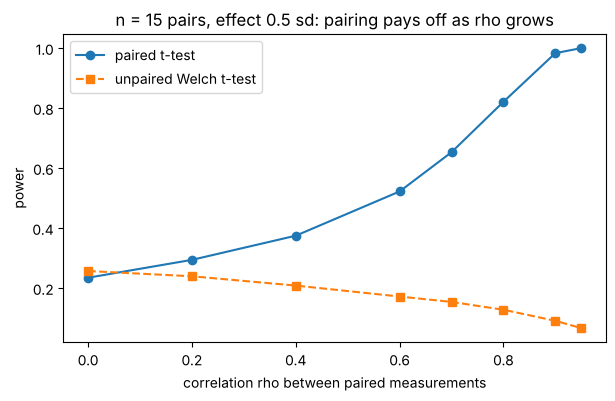

rho = 0.00: power paired 0.234   unpaired 0.257
rho = 0.20: power paired 0.294   unpaired 0.239
rho = 0.40: power paired 0.374   unpaired 0.208
rho = 0.60: power paired 0.522   unpaired 0.172
rho = 0.70: power paired 0.653   unpaired 0.154
rho = 0.80: power paired 0.821   unpaired 0.128
rho = 0.90: power paired 0.983   unpaired 0.091
rho = 0.95: power paired 1.000   unpaired 0.067


In [6]:
def paired_vs_unpaired_power(rho, n=15, delta=0.5, reps=4_000, alpha=0.05):
    z1 = rng.standard_normal((reps, n)); z2 = rng.standard_normal((reps, n))
    x = z1
    y = rho * z1 + np.sqrt(1 - rho**2) * z2 + delta          # correlated partner, shifted by delta
    p_paired = stats.ttest_rel(x, y, axis=1).pvalue
    p_unpaired = stats.ttest_ind(x, y, axis=1, equal_var=False).pvalue
    return (p_paired < alpha).mean(), (p_unpaired < alpha).mean()

rhos = np.array([0.0, 0.2, 0.4, 0.6, 0.7, 0.8, 0.9, 0.95])
pw = np.array([paired_vs_unpaired_power(r) for r in rhos])
plt.plot(rhos, pw[:, 0], "o-", label="paired t-test")
plt.plot(rhos, pw[:, 1], "s--", label="unpaired Welch t-test")
plt.xlabel("correlation rho between paired measurements"); plt.ylabel("power")
plt.title("n = 15 pairs, effect 0.5 sd: pairing pays off as rho grows"); plt.legend(); plt.show()
for r, (pp, pu) in zip(rhos, pw):
    print(f"rho = {r:.2f}: power paired {pp:.3f}   unpaired {pu:.3f}")

At $\rho = 0$ the two tests are nearly equal (the paired test even loses a little, having $n - 1$ instead of
about $2n - 2$ degrees of freedom); at $\rho = 0.9$ the paired test detects the effect almost always while the
unpaired one still misses it more than half the time. This is why before/after designs, repeated measures,
and model comparisons on *shared* folds or test examples are analysed paired.

**Try it yourself:** set `delta = 0.3` and `n = 30` — does the crossover point move?

## 4. Proportions and the chi-square test

Conversions by variant: A 200/4000, B 240/4000. Two-proportion z-test with the pooled rate
$\bar\theta = (x_1 + x_2)/(n_1 + n_2)$, and the same data as a $2 \times 2$ table with Pearson's
$\chi^2 = \sum (O - E)^2/E$, $E_{ij} = R_i C_j / N$. For a $2 \times 2$ table $\chi^2 = z^2$ exactly.
We also run a small-sample table through Fisher's exact test and Yates's correction.

In [7]:
def two_prop_z(x1, n1, x2, n2):
    p1, p2 = x1 / n1, x2 / n2
    pbar = (x1 + x2) / (n1 + n2)
    se0 = np.sqrt(pbar * (1 - pbar) * (1 / n1 + 1 / n2))          # pooled SE, valid under H0
    z = (p2 - p1) / se0
    se_ci = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)      # unpooled SE for the interval
    return z, 2 * stats.norm.sf(abs(z)), (p2 - p1 - 1.96 * se_ci, p2 - p1 + 1.96 * se_ci)

def chi2_independence(table):
    table = np.asarray(table, float)
    expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / table.sum()
    chi2 = ((table - expected)**2 / expected).sum()
    dof = (table.shape[0] - 1) * (table.shape[1] - 1)
    return chi2, stats.chi2.sf(chi2, dof), dof, expected

z, p_z, ci = two_prop_z(200, 4000, 240, 4000)
print(f"two-proportion z-test: z = {z:.4f}, p = {p_z:.4f}, 95% CI for the lift [{ci[0]:.5f}, {ci[1]:.5f}]")

table = np.array([[200, 3800], [240, 3760]])
chi2, p_chi, dof, E = chi2_independence(table)
print(f"\nexpected counts under independence:\n{E}")
print(f"chi-square by hand: chi2 = {chi2:.4f}, dof = {dof}, p = {p_chi:.4f}    z^2 = {z**2:.4f}")
sp = stats.chi2_contingency(table, correction=False)
print(f"scipy chi2_contingency(correction=False): chi2 = {sp.statistic:.4f}, p = {sp.pvalue:.4f}")

# small-sample table: nausea 30/200 treated vs 18/200 placebo
small = np.array([[30, 170], [18, 182]])
chi2_s, p_s, _, E_s = chi2_independence(small)
print(f"\nside-effect table: expected = {E_s[0].round(1)} per row;  chi2 = {chi2_s:.3f}, p = {p_s:.4f}")
print(f"with Yates's correction: p = {stats.chi2_contingency(small, correction=True).pvalue:.4f}")
print(f"Fisher's exact test   : p = {stats.fisher_exact(small).pvalue:.4f}")

two-proportion z-test: z = 1.9616, p = 0.0498, 95% CI for the lift [0.00001, 0.01999]

expected counts under independence:
[[ 220. 3780.]
 [ 220. 3780.]]
chi-square by hand: chi2 = 3.8480, dof = 1, p = 0.0498    z^2 = 3.8480
scipy chi2_contingency(correction=False): chi2 = 3.8480, p = 0.0498

side-effect table: expected = [ 24. 176.] per row;  chi2 = 3.409, p = 0.0648
with Yates's correction: p = 0.0905
Fisher's exact test   : p = 0.0897


$z^2 = 3.848 = \chi^2$ to all shown digits, and the p-values coincide: the chi-square test of a $2 \times 2$
table *is* the two-sided two-proportion z-test. The confidence interval for the lift,
$[0.00001, 0.020]$, excludes zero by a hair just as $p = 0.0498$ sits a hair under $0.05$ — Section 6 explains
why these must agree. On the small side-effect table the three p-values ($0.065$, $0.091$, $0.090$) disagree
noticeably; none reaches $0.05$, but the interval for the excess nausea rate stretches up to 12 percentage
points, which is the number a safety review should read.

## 5. Permutation and rank tests on skewed revenue data

Revenue per user is 95% zeros plus a long right tail. Under $H_0$ (treatment changes nothing) the labels
are arbitrary, so we shuffle them, recompute the difference of means, and read the p-value off the
shuffled distribution:

$$\hat p = \frac{1 + \#\{b : |T^{(b)}| \ge |t_{\text{obs}}|\}}{B + 1}.$$

We then compute the Mann–Whitney $U$ statistic by counting pairs, apply its tie-corrected normal
approximation, and compare both with scipy and with Welch's t-test.

mean revenue per user: A = 5.40, B = 5.95, difference = 0.56
share of zeros: 0.941 / 0.934;  largest order = 1026



permutation test: p = 0.6293   (B = 5000 shuffles)
Welch t-test    : p = 0.6212


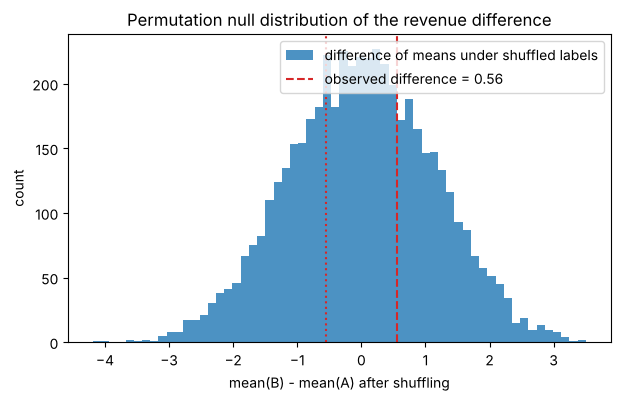

In [8]:
def revenue(n, p_buy, rng):
    buys = rng.random(n) < p_buy
    return np.where(buys, rng.lognormal(mean=np.log(60), sigma=1.0, size=n), 0.0)

n_users = 2_000
rev_a = revenue(n_users, 0.050, rng)        # control: 5% buy
rev_b = revenue(n_users, 0.065, rng)        # treatment: 6.5% buy, same basket distribution
t_obs = rev_b.mean() - rev_a.mean()
print(f"mean revenue per user: A = {rev_a.mean():.2f}, B = {rev_b.mean():.2f}, difference = {t_obs:.2f}")
print(f"share of zeros: {np.mean(rev_a == 0):.3f} / {np.mean(rev_b == 0):.3f};  largest order = {max(rev_a.max(), rev_b.max()):.0f}")

pooled = np.concatenate([rev_a, rev_b])
B = 5_000
perm_diffs = np.empty(B)
for b in range(B):
    perm = rng.permutation(pooled)
    perm_diffs[b] = perm[n_users:].mean() - perm[:n_users].mean()
p_perm = (1 + np.sum(np.abs(perm_diffs) >= abs(t_obs))) / (B + 1)
print(f"\npermutation test: p = {p_perm:.4f}   (B = {B} shuffles)")
print(f"Welch t-test    : p = {stats.ttest_ind(rev_b, rev_a, equal_var=False).pvalue:.4f}")

plt.hist(perm_diffs, bins=60, alpha=0.8, label="difference of means under shuffled labels")
plt.axvline(t_obs, color="C3", ls="--", label=f"observed difference = {t_obs:.2f}")
plt.axvline(-t_obs, color="C3", ls=":")
plt.xlabel("mean(B) - mean(A) after shuffling"); plt.ylabel("count")
plt.title("Permutation null distribution of the revenue difference"); plt.legend(); plt.show()

In [9]:
def mann_whitney_u(a, b):
    # U = number of (a_i, b_j) pairs with a_i > b_j, ties counting one half
    gt = (a[:, None] > b[None, :]).sum()
    eq = (a[:, None] == b[None, :]).sum()
    return gt + 0.5 * eq

def mann_whitney_p(a, b):
    n1, n2 = len(a), len(b); N = n1 + n2
    u1 = mann_whitney_u(a, b)
    u = max(u1, n1 * n2 - u1)                                   # two-sided: the larger of U_A, U_B
    mu = n1 * n2 / 2
    _, ties = np.unique(np.concatenate([a, b]), return_counts=True)
    var = n1 * n2 / 12 * ((N + 1) - (ties**3 - ties).sum() / (N * (N - 1)))   # tie-corrected variance
    z = (u - mu - 0.5) / np.sqrt(var)                           # continuity correction
    return u1, 2 * stats.norm.sf(z)

u1, p_mw = mann_whitney_p(rev_b, rev_a)
sp = stats.mannwhitneyu(rev_b, rev_a, alternative="two-sided", method="asymptotic")
print(f"Mann-Whitney by hand: U = {u1:.1f}, p = {p_mw:.4f}    scipy: U = {sp.statistic:.1f}, p = {sp.pvalue:.4f}")
print(f"P(a random B user out-spends a random A user) = U / (n1 n2) = {u1 / (n_users**2):.4f}   (0.5 under H0)")

# a tiny example where the exact permutation distribution can be enumerated
from itertools import combinations
A3, B3 = np.array([12., 15, 11]), np.array([9., 8, 10])
all6 = np.concatenate([A3, B3]); obs = A3.mean() - B3.mean()
diffs = np.array([all6[list(idx)].mean() - np.delete(all6, list(idx)).mean() for idx in combinations(range(6), 3)])
print(f"\n3 vs 3 example: {len(diffs)} splits, observed diff {obs:.2f}, exact two-sided p = {np.mean(np.abs(diffs) >= abs(obs) - 1e-12):.3f}")
print(f"Welch t-test on the same six numbers: p = {stats.ttest_ind(A3, B3, equal_var=False).pvalue:.3f}  (leans on normality of three points)")

Mann-Whitney by hand: U = 2012959.0, p = 0.3968    scipy: U = 2012959.0, p = 0.3968
P(a random B user out-spends a random A user) = U / (n1 n2) = 0.5032   (0.5 under H0)

3 vs 3 example: 20 splits, observed diff 3.67, exact two-sided p = 0.100
Welch t-test on the same six numbers: p = 0.074  (leans on normality of three points)


Two lessons in one output. First, the treatment *does* raise the purchase rate (6.5% against 5%), yet with
2,000 users per arm neither test comes close to significance: a handful of large orders dominates the means
(one order of about 1,000 against an average of 5–6), so the standard error of the difference is huge. This is
the everyday reality of revenue metrics — they need far more users than conversion metrics, or a more robust
statistic. Second, the permutation p-value and Welch's p-value are close here because the central limit
theorem has had 4,000 observations to work with even for this ugly distribution; the permutation test's
advantage is that it would remain exact with 50 users per arm, or for a trimmed mean or a median, where the
t-test's approximation fails. Mann–Whitney asks a different question — does a random B user out-spend a random
A user more than half the time? — and the hand computation matches scipy's once ties and the continuity
correction are handled. The 3-vs-3 example shows the granularity of exact tests: the smallest possible
two-sided p-value is $2/20 = 0.10$, so no result from three observations per group can be "significant at 5%".

**Try it yourself:** replace the statistic in the permutation loop by the difference of *medians* or of
20%-trimmed means (`stats.trim_mean(x, 0.2)`) — the code does not change otherwise. That is the point.

## 6. Confidence intervals and tests are the same thing

A level-$\alpha$ test of $\theta = \theta_0$ rejects exactly when $\theta_0$ lies outside the $(1 - \alpha)$
confidence interval built from the same statistic. We verify this on 5,000 simulated two-sample
experiments. Then the reverse question — *are two things equivalent?* — via Schuirmann's two one-sided
tests (TOST): equivalence within $\pm\Delta$ at level $\alpha$ holds iff the $(1 - 2\alpha)$ interval lies
inside $(-\Delta, \Delta)$.

experiments where test and interval agree: 1.0000   (rejections: 0.142)
interval covers the true difference -0.3 in 0.9500 of experiments
diff 0.5, SE 0.4: classic p = 0.211 (never rejects 'no difference');  TOST p = 0.0001, 90% CI [-0.16, +1.16] -> equivalent within +/-2: True
diff 0.5, SE 0.8: classic p = 0.532 (never rejects 'no difference');  TOST p = 0.0304, 90% CI [-0.82, +1.82] -> equivalent within +/-2: True
diff 0.5, SE 1.2: classic p = 0.677 (never rejects 'no difference');  TOST p = 0.1056, 90% CI [-1.47, +2.47] -> equivalent within +/-2: False
diff 0.5, SE 2.0: classic p = 0.803 (never rejects 'no difference');  TOST p = 0.2266, 90% CI [-2.79, +3.79] -> equivalent within +/-2: False


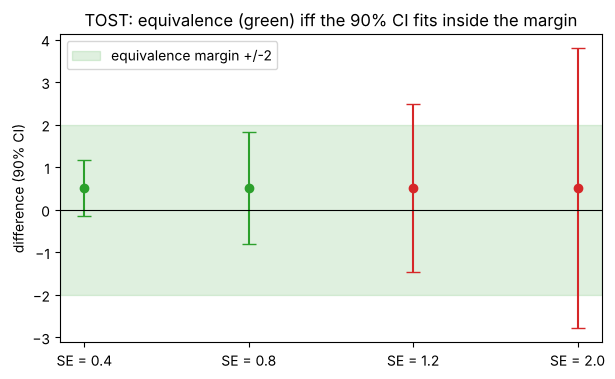

In [10]:
reps, n = 5_000, 30
x = rng.normal(0.0, 1.0, size=(reps, n)); y = rng.normal(0.3, 1.5, size=(reps, n))
res = stats.ttest_ind(x, y, axis=1, equal_var=False)
diff = x.mean(axis=1) - y.mean(axis=1)
se = np.sqrt(x.var(axis=1, ddof=1) / n + y.var(axis=1, ddof=1) / n)
tcrit = stats.t.ppf(0.975, res.df)
lo, hi = diff - tcrit * se, diff + tcrit * se
reject = res.pvalue < 0.05
excludes_zero = (lo > 0) | (hi < 0)
print(f"experiments where test and interval agree: {np.mean(reject == excludes_zero):.4f}   (rejections: {reject.mean():.3f})")
print(f"interval covers the true difference -0.3 in {np.mean((lo <= -0.3) & (-0.3 <= hi)):.4f} of experiments")

def tost(diff, se, margin, alpha=0.05):
    # H0: theta <= -margin  OR  theta >= margin ; reject both to conclude equivalence
    p_lower = stats.norm.sf((diff + margin) / se)
    p_upper = stats.norm.sf((margin - diff) / se)
    zc = stats.norm.ppf(1 - alpha)
    ci90 = (diff - zc * se, diff + zc * se)
    return max(p_lower, p_upper), (p_lower < alpha) and (p_upper < alpha), ci90

for se_ in (0.4, 0.8, 1.2, 2.0):
    p_tost, equiv, ci90 = tost(0.5, se_, margin=2.0)
    p_classic = 2 * stats.norm.sf(abs(0.5 / se_))
    print(f"diff 0.5, SE {se_:.1f}: classic p = {p_classic:.3f} (never rejects 'no difference');  TOST p = {p_tost:.4f}, "
          f"90% CI [{ci90[0]:+.2f}, {ci90[1]:+.2f}] -> equivalent within +/-2: {equiv}")

ses = np.array([0.4, 0.8, 1.2, 2.0])
plt.axhspan(-2, 2, color="C2", alpha=0.15, label="equivalence margin +/-2")
for i, se_ in enumerate(ses):
    _, equiv, ci90 = tost(0.5, se_, 2.0)
    plt.errorbar(i, 0.5, yerr=[[0.5 - ci90[0]], [ci90[1] - 0.5]], fmt="o", capsize=5, color="C2" if equiv else "C3")
plt.axhline(0, color="k", lw=0.8)
plt.xticks(range(len(ses)), [f"SE = {s}" for s in ses]); plt.ylabel("difference (90% CI)")
plt.title("TOST: equivalence (green) iff the 90% CI fits inside the margin"); plt.legend(loc="upper left"); plt.show()

Test and interval agree in 100% of experiments, because they are two readings of one inequality. The TOST
rows show why "not significant" is not "equivalent": all four classic tests fail to reject the null of no
difference, yet only the two precise studies demonstrate equivalence within $\pm 2$; the imprecise ones are
simply inconclusive. A generic drug's bioequivalence, or a quantised model's "no loss of accuracy", must be
shown this way, with the margin fixed in advance.

## 7. Multiple comparisons: Bonferroni, Holm and Benjamini–Hochberg

With $m$ independent true nulls tested at $\alpha$, $P(\text{at least one false rejection}) = 1 - (1 - \alpha)^m$.
We confirm this by simulation, implement the three standard corrections as *adjusted p-values*
(reject when $\tilde p \le \alpha$), apply them to the ten p-values of the guide, and then measure what each
procedure actually controls — FWER, FDR and power — on a simulated screen of 100 hypotheses of which 20 are
real.

* Bonferroni: $\tilde p_i = \min(m\,p_i, 1)$.
* Holm (step-down): sort; $\tilde p_{(i)} = \min\big(1, \max_{j \le i}(m - j + 1)\,p_{(j)}\big)$.
* Benjamini–Hochberg (step-up): sort; $\tilde p_{(i)} = \min\big(1, \min_{j \ge i} \tfrac{m}{j}\,p_{(j)}\big)$.

In [11]:
def bonferroni_adjust(p):
    p = np.asarray(p, float)
    return np.minimum(p * len(p), 1.0)

def holm_adjust(p):
    p = np.asarray(p, float); m = len(p)
    order = np.argsort(p)
    scaled = p[order] * (m - np.arange(m))                       # (m - i + 1) p_(i), i = 1..m
    adj_sorted = np.minimum(np.maximum.accumulate(scaled), 1.0)  # enforce monotonicity downwards
    adj = np.empty(m); adj[order] = adj_sorted
    return adj

def bh_adjust(p):
    p = np.asarray(p, float); m = len(p)
    order = np.argsort(p)
    scaled = p[order] * m / np.arange(1, m + 1)                  # (m / i) p_(i)
    adj_sorted = np.minimum(np.minimum.accumulate(scaled[::-1])[::-1], 1.0)   # enforce monotonicity upwards
    adj = np.empty(m); adj[order] = adj_sorted
    return adj

# FWER blow-up under the global null
for m in (1, 2, 5, 10, 20, 50, 100):
    pvals = rng.random((20_000, m))
    print(f"m = {m:3d}: simulated P(any p < 0.05) = {(pvals.min(axis=1) < 0.05).mean():.3f}   formula 1 - 0.95^m = {1 - 0.95**m:.3f}")

p10 = np.array([0.001, 0.011, 0.012, 0.019, 0.040, 0.045, 0.200, 0.350, 0.600, 0.900])
print(f"\n{'p':>8s} {'Bonferroni':>11s} {'Holm':>8s} {'BH':>8s}")
for p_, b_, h_, q_ in zip(p10, bonferroni_adjust(p10), holm_adjust(p10), bh_adjust(p10)):
    print(f"{p_:8.3f} {b_:11.4f} {h_:8.4f} {q_:8.4f}")
print("rejections at 0.05 -> uncorrected:", (p10 <= 0.05).sum(), " Bonferroni:", (bonferroni_adjust(p10) <= 0.05).sum(),
      " Holm:", (holm_adjust(p10) <= 0.05).sum(), " BH:", (bh_adjust(p10) <= 0.05).sum())

m =   1: simulated P(any p < 0.05) = 0.051   formula 1 - 0.95^m = 0.050
m =   2: simulated P(any p < 0.05) = 0.093   formula 1 - 0.95^m = 0.098
m =   5: simulated P(any p < 0.05) = 0.228   formula 1 - 0.95^m = 0.226
m =  10: simulated P(any p < 0.05) = 0.398   formula 1 - 0.95^m = 0.401
m =  20: simulated P(any p < 0.05) = 0.639   formula 1 - 0.95^m = 0.642
m =  50: simulated P(any p < 0.05) = 0.924   formula 1 - 0.95^m = 0.923
m = 100: simulated P(any p < 0.05) = 0.993   formula 1 - 0.95^m = 0.994

       p  Bonferroni     Holm       BH
   0.001      0.0100   0.0100   0.0100
   0.011      0.1100   0.0990   0.0400
   0.012      0.1200   0.0990   0.0400
   0.019      0.1900   0.1330   0.0475
   0.040      0.4000   0.2400   0.0750
   0.045      0.4500   0.2400   0.0750
   0.200      1.0000   0.8000   0.2857
   0.350      1.0000   1.0000   0.4375
   0.600      1.0000   1.0000   0.6667
   0.900      1.0000   1.0000   0.9000
rejections at 0.05 -> uncorrected: 6  Bonferroni: 1  Holm: 1  BH: 

method            FWER     FDR   power
uncorrected      0.979   0.185   0.850
Bonferroni       0.038   0.006   0.319
Holm             0.041   0.007   0.325
BH (q = 0.05)    0.403   0.039   0.606


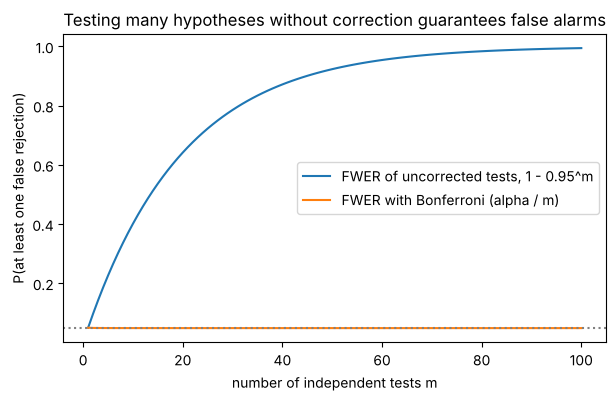

In [12]:
# what does each procedure control? 100 hypotheses, 20 real effects (z-shift 3), 2000 repetitions
m, m1, reps = 100, 20, 2_000
is_alt = np.zeros(m, bool); is_alt[:m1] = True
methods = {"uncorrected": lambda p: p, "Bonferroni": bonferroni_adjust, "Holm": holm_adjust, "BH (q = 0.05)": bh_adjust}
stats_ = {k: dict(fwer=0.0, fdr=0.0, power=0.0) for k in methods}
for _ in range(reps):
    z = rng.standard_normal(m) + 3.0 * is_alt
    p = 2 * stats.norm.sf(np.abs(z))
    for name, adjust in methods.items():
        rej = adjust(p) <= 0.05
        V, R = np.sum(rej & ~is_alt), rej.sum()
        stats_[name]["fwer"] += V >= 1
        stats_[name]["fdr"] += V / R if R else 0.0
        stats_[name]["power"] += np.mean(rej[is_alt])
print(f"{'method':14s} {'FWER':>7s} {'FDR':>7s} {'power':>7s}")
for name, s in stats_.items():
    print(f"{name:14s} {s['fwer'] / reps:7.3f} {s['fdr'] / reps:7.3f} {s['power'] / reps:7.3f}")

ms = np.arange(1, 101)
plt.plot(ms, 1 - 0.95**ms, label="FWER of uncorrected tests, 1 - 0.95^m")
plt.plot(ms, 1 - (1 - 0.05 / ms)**ms, label="FWER with Bonferroni (alpha / m)")
plt.axhline(0.05, color="gray", ls=":")
plt.xlabel("number of independent tests m"); plt.ylabel("P(at least one false rejection)")
plt.title("Testing many hypotheses without correction guarantees false alarms"); plt.legend(); plt.show()

On the ten p-values Bonferroni and Holm reject only the smallest, while BH rejects four — including
$p = 0.011$, which exceeded its own threshold $0.010$ but is swept in by the step-up rule. The simulation
shows the trade: uncorrected testing has a family-wise error rate near 1 (some false discovery in almost
every screen); Bonferroni and Holm hold it at $0.05$ but find only about 40% of the real effects; BH lets the
FDR be about $0.04$ (close to its guarantee $q\,m_0/m = 0.04$) and in exchange finds about 70% of them. Which
guarantee you want depends on the cost of one false lead versus one missed discovery.

**Try it yourself:** set `m1 = 50` (half the hypotheses real) and re-run — BH's power rises while the FDR
bound $q\,m_0/m$ falls to $0.025$; Bonferroni's power does not move. Why?

## 8. Designing experiments: what randomisation and blocking buy

Outcome: minutes on site. Mobile users average 2 minutes, desktop users 6 minutes (sd 1.5 within device),
and the new design adds **+0.5 minutes for everyone**. In the observational roll-out the feature was opted
into mostly by mobile users; in the experiment, assignment is a coin flip. We compare the naive estimates,
then measure how much *stratified* randomisation (blocking on device) tightens the estimate.

In [13]:
N = 20_000
mobile = rng.random(N) < 0.5
base = np.where(mobile, 2.0, 6.0)
true_effect = 0.5

# observational roll-out: mobile users opt in 80% of the time, desktop users 20%
treated_obs = rng.random(N) < np.where(mobile, 0.8, 0.2)
y_obs = base + true_effect * treated_obs + rng.normal(0, 1.5, N)
naive = y_obs[treated_obs].mean() - y_obs[~treated_obs].mean()
print(f"observational: treated mean {y_obs[treated_obs].mean():.2f} vs control {y_obs[~treated_obs].mean():.2f} -> naive effect {naive:+.2f} (truth {true_effect:+.2f})")
for dev, mask in (("mobile", mobile), ("desktop", ~mobile)):
    eff = y_obs[mask & treated_obs].mean() - y_obs[mask & ~treated_obs].mean()
    print(f"   within {dev:7s}: effect {eff:+.2f}   (treated share {treated_obs[mask].mean():.2f})")

# randomised experiment on the same population
treated_rct = rng.random(N) < 0.5
y_rct = base + true_effect * treated_rct + rng.normal(0, 1.5, N)
print(f"randomised   : effect {y_rct[treated_rct].mean() - y_rct[~treated_rct].mean():+.2f}   (mobile share treated {mobile[treated_rct].mean():.3f} vs control {mobile[~treated_rct].mean():.3f})")

# blocking: simple vs stratified randomisation, n = 400 users, 2000 replications
def one_experiment(stratified, n=400):
    mob = rng.random(n) < 0.5
    if stratified:
        t = np.zeros(n, bool)
        for mask in (mob, ~mob):                      # exactly half of each device group treated
            idx = np.flatnonzero(mask); t[rng.permutation(idx)[:len(idx) // 2]] = True
    else:
        t = rng.random(n) < 0.5
    y = np.where(mob, 2.0, 6.0) + true_effect * t + rng.normal(0, 1.5, n)
    return y[t].mean() - y[~t].mean()

est_simple = np.array([one_experiment(False) for _ in range(2_000)])
est_strat = np.array([one_experiment(True) for _ in range(2_000)])
print(f"\nestimate of the effect over 2000 experiments (n = 400):")
print(f"   simple randomisation    : mean {est_simple.mean():.3f}, sd {est_simple.std():.3f}")
print(f"   stratified by device    : mean {est_strat.mean():.3f}, sd {est_strat.std():.3f}")
print(f"   theory: sd simple = sqrt(2 (1.5^2 + 2^2) / 200) = {np.sqrt(2 * (1.5**2 + 2.0**2) / 200):.3f};  stratified = sqrt(2 * 1.5^2 / 200) = {np.sqrt(2 * 1.5**2 / 200):.3f}")

# A/A test: two arms with identical treatment should reject 5% of the time
p_aa = np.array([stats.ttest_ind(*np.split(rng.permutation(y_rct[~treated_rct][:2_000]), 2), equal_var=False).pvalue for _ in range(2_000)])
print(f"\nA/A test rejection rate at alpha = 0.05: {(p_aa < 0.05).mean():.3f}")

observational: treated mean 3.33 vs control 5.21 -> naive effect -1.88 (truth +0.50)
   within mobile : effect +0.48   (treated share 0.80)
   within desktop: effect +0.51   (treated share 0.20)
randomised   : effect +0.50   (mobile share treated 0.500 vs control 0.495)



estimate of the effect over 2000 experiments (n = 400):
   simple randomisation    : mean 0.503, sd 0.249
   stratified by device    : mean 0.492, sd 0.149
   theory: sd simple = sqrt(2 (1.5^2 + 2^2) / 200) = 0.250;  stratified = sqrt(2 * 1.5^2 / 200) = 0.150



A/A test rejection rate at alpha = 0.05: 0.056


The observational estimate has the *wrong sign* ($-1.9$ against a truth of $+0.5$) even though the effect is
positive within each device type: treated users are mostly mobile users, who spend less time regardless —
Simpson's paradox, produced by confounded assignment. Randomisation makes the treated and control groups
have the same device mix and recovers $+0.5$. Blocking then removes the device variance from the comparison:
the standard deviation of the estimate drops from about $0.25$ to $0.15$, equivalent to nearly tripling the
sample size for free. The A/A test rejecting at the nominal 5% is the health check that the pipeline is honest.

## 9. Peeking: checking a running test and stopping early

Two arms, standard normal noise, 1,000 users per arm in total. We look at the z-statistic after every
batch and stop as soon as $|Z| > 1.96$. Under $H_0$ the planned single look rejects 5% of the time; with
repeated looks the running statistic is a random walk that gets many chances to cross. Then the fix:
Pocock's constant boundary for a pre-specified number of looks.

 1 look(s): P(stop early with 'significant' result | H0) = 0.053   (tabulated 0.050; at the final look alone 0.053)
 2 look(s): P(stop early with 'significant' result | H0) = 0.084   (tabulated 0.083; at the final look alone 0.050)


 5 look(s): P(stop early with 'significant' result | H0) = 0.143   (tabulated 0.142; at the final look alone 0.054)


10 look(s): P(stop early with 'significant' result | H0) = 0.193   (tabulated 0.193; at the final look alone 0.050)
20 look(s): P(stop early with 'significant' result | H0) = 0.249   (tabulated 0.248; at the final look alone 0.060)


50 look(s): P(stop early with 'significant' result | H0) = 0.325   (tabulated 0.320; at the final look alone 0.051)


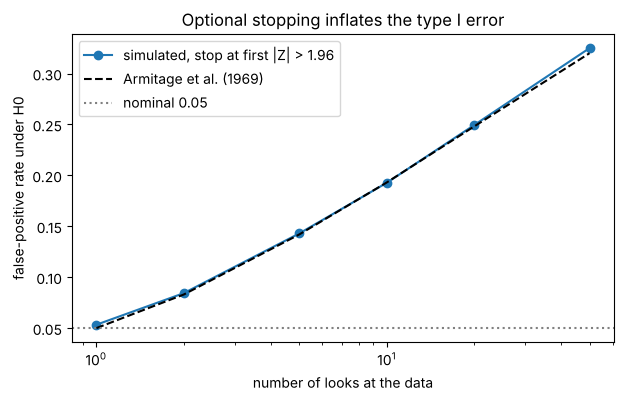

Pocock boundary |Z| > 2.413 with  5 looks: false-positive rate = 0.044
Pocock boundary |Z| > 2.555 with 10 looks: false-positive rate = 0.050
Pocock boundary |Z| > 2.672 with 20 looks: false-positive rate = 0.051



among null experiments stopped early, median stopping look = 4 of 20; mean |Z| at stopping = 2.22 (an 'effect' that does not exist)


In [14]:
def peeking_fpr(n_looks, n_per_look, n_sims, z_crit=1.96):
    a = rng.standard_normal((n_sims, n_looks, n_per_look)).sum(axis=2)
    b = rng.standard_normal((n_sims, n_looks, n_per_look)).sum(axis=2)
    n_cum = np.arange(1, n_looks + 1) * n_per_look
    z = (b.cumsum(axis=1) - a.cumsum(axis=1)) / np.sqrt(2 * n_cum)   # z-statistic at each look
    any_cross = np.any(np.abs(z) > z_crit, axis=1)
    return any_cross.mean(), (np.abs(z[:, -1]) > z_crit).mean(), z

looks = [1, 2, 5, 10, 20, 50]
armitage = {1: 0.05, 2: 0.083, 5: 0.142, 10: 0.193, 20: 0.248, 50: 0.320}   # Armitage, McPherson & Rowe (1969)
fprs = []
for L in looks:
    fpr_any, fpr_final, _ = peeking_fpr(L, 1000 // L, 3_000)
    fprs.append(fpr_any)
    print(f"{L:2d} look(s): P(stop early with 'significant' result | H0) = {fpr_any:.3f}   (tabulated {armitage[L]:.3f}; at the final look alone {fpr_final:.3f})")

plt.plot(looks, fprs, "o-", label="simulated, stop at first |Z| > 1.96")
plt.plot(looks, [armitage[L] for L in looks], "k--", label="Armitage et al. (1969)")
plt.axhline(0.05, color="gray", ls=":", label="nominal 0.05")
plt.xscale("log"); plt.xlabel("number of looks at the data"); plt.ylabel("false-positive rate under H0")
plt.title("Optional stopping inflates the type I error"); plt.legend(); plt.show()

# the fix: Pocock boundaries for a pre-specified number of looks
for L, zb in ((5, 2.413), (10, 2.555), (20, 2.672)):
    fpr_any, _, _ = peeking_fpr(L, 1000 // L, 3_000, z_crit=zb)
    print(f"Pocock boundary |Z| > {zb} with {L:2d} looks: false-positive rate = {fpr_any:.3f}")
_, _, z20 = peeking_fpr(20, 50, 3_000)
stopped = np.argmax(np.abs(z20) > 1.96, axis=1); ever = np.any(np.abs(z20) > 1.96, axis=1)
print(f"\namong null experiments stopped early, median stopping look = {np.median(stopped[ever]) + 1:.0f} of 20;"
      f" mean |Z| at stopping = {np.abs(z20[ever, stopped[ever]]).mean():.2f} (an 'effect' that does not exist)")

The simulation reproduces the classical table: one look, 5%; five looks, 14%; twenty looks, 25%. Note the
last column — at the *final* look alone the rate is still 5%; the inflation comes entirely from the option
to stop earlier. Pocock's boundaries restore the nominal rate at the price of needing $|Z| > 2.4$ to $2.7$
instead of $1.96$; O'Brien–Fleming boundaries spend less $\alpha$ early and are the clinical-trial default.
The stopped experiments report large "effects" that are pure noise — the winner's curse of optional stopping.

**Try it yourself:** replace `z_crit=1.96` by the Bonferroni-per-look value `stats.norm.ppf(1 - 0.025 / L)`
for `L = 10` — it is valid, but how much stricter than Pocock's $2.555$ is it?

## 10. Comparing two classifiers properly

Logistic regression versus $k$-nearest neighbours on the bundled breast-cancer data. First a single
held-out set: the two models' per-example results are *paired*, so we use **McNemar's test** on the
discordant counts $b$ (A right, B wrong) and $c$ (B right, A wrong),

$$\chi^2 = \frac{(|b - c| - 1)^2}{b + c}, \qquad \text{exact: } b \sim \text{Binomial}(b + c, \tfrac12).$$

Then repeated stratified cross-validation ($10 \times 5$-fold, $J = 50$ paired differences) with the naive
paired t-test and the **Nadeau–Bengio** correction, which inflates the variance by
$(1/J + n_{\text{test}}/n_{\text{train}})/(1/J)$ to account for the overlap between training sets.

In [15]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold

X, y = load_breast_cancer(return_X_y=True)
model_a = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5_000))
model_b = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

def mcnemar(y_true, pred_a, pred_b):
    right_a, right_b = pred_a == y_true, pred_b == y_true
    b = int(np.sum(right_a & ~right_b)); c = int(np.sum(~right_a & right_b))
    chi2_cc = (abs(b - c) - 1)**2 / (b + c) if b + c > 0 else 0.0
    p_cc = stats.chi2.sf(chi2_cc, 1)
    p_exact = stats.binomtest(min(b, c), b + c, 0.5).pvalue if b + c > 0 else 1.0
    return b, c, chi2_cc, p_cc, p_exact

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.4, random_state=0, stratify=y)
pred_a = model_a.fit(X_tr, y_tr).predict(X_te)
pred_b = model_b.fit(X_tr, y_tr).predict(X_te)
acc_a, acc_b = np.mean(pred_a == y_te), np.mean(pred_b == y_te)
b, c, chi2_cc, p_cc, p_exact = mcnemar(y_te, pred_a, pred_b)
print(f"held-out set of {len(y_te)} examples: accuracy logistic = {acc_a:.4f}, kNN = {acc_b:.4f}, gap = {acc_a - acc_b:+.4f}")
print(f"discordant examples: logistic right & kNN wrong b = {b}, kNN right & logistic wrong c = {c}  (both right/wrong: {len(y_te) - b - c})")
print(f"McNemar: chi2 (continuity-corrected) = {chi2_cc:.3f}, p = {p_cc:.3f};  exact binomial p = {p_exact:.3f}")
se_single = np.sqrt(acc_a * (1 - acc_a) / len(y_te))
print(f"for scale: the standard error of one accuracy on this test set is {se_single:.4f}")

held-out set of 228 examples: accuracy logistic = 0.9649, kNN = 0.9518, gap = +0.0132
discordant examples: logistic right & kNN wrong b = 6, kNN right & logistic wrong c = 3  (both right/wrong: 219)
McNemar: chi2 (continuity-corrected) = 0.444, p = 0.505;  exact binomial p = 0.508
for scale: the standard error of one accuracy on this test set is 0.0122


50 paired fold differences (logistic - kNN): mean +0.0106, sd 0.0179, folds favouring logistic: 33
naive paired t-test        : t = 4.16, p = 0.0001   (scipy ttest_1samp: p = 0.0001)
Nadeau-Bengio corrected    : t = 1.14, p = 0.2608   (variance inflated by factor 13.4)


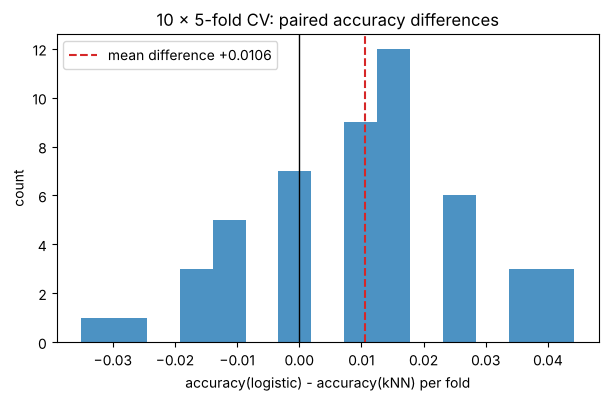

In [16]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
diffs = []
for tr, te in cv.split(X, y):
    a = model_a.fit(X[tr], y[tr]).score(X[te], y[te])
    b_ = model_b.fit(X[tr], y[tr]).score(X[te], y[te])
    diffs.append(a - b_)
diffs = np.array(diffs); J = len(diffs)
n_test, n_train = len(te), len(tr)

t_naive = diffs.mean() / (diffs.std(ddof=1) / np.sqrt(J))
p_naive = 2 * stats.t.sf(abs(t_naive), J - 1)
rho = n_test / n_train
t_nb = diffs.mean() / np.sqrt((1 / J + rho) * diffs.var(ddof=1))
p_nb = 2 * stats.t.sf(abs(t_nb), J - 1)
print(f"{J} paired fold differences (logistic - kNN): mean {diffs.mean():+.4f}, sd {diffs.std(ddof=1):.4f}, folds favouring logistic: {(diffs > 0).sum()}")
print(f"naive paired t-test        : t = {t_naive:.2f}, p = {p_naive:.4f}   (scipy ttest_1samp: p = {stats.ttest_1samp(diffs, 0).pvalue:.4f})")
print(f"Nadeau-Bengio corrected    : t = {t_nb:.2f}, p = {p_nb:.4f}   (variance inflated by factor {(1 / J + rho) / (1 / J):.1f})")

plt.hist(diffs, bins=15, alpha=0.8)
plt.axvline(0, color="k", lw=1); plt.axvline(diffs.mean(), color="C3", ls="--", label=f"mean difference {diffs.mean():+.4f}")
plt.xlabel("accuracy(logistic) - accuracy(kNN) per fold"); plt.ylabel("count")
plt.title("10 x 5-fold CV: paired accuracy differences"); plt.legend(); plt.show()

The two tests tell one story once done properly. On the single split the models differ on only nine of 228
examples, split 6:3, and McNemar cannot distinguish them ($p \approx 0.5$) — the 1.3-point accuracy gap is
about one standard error of a single accuracy. In repeated cross-validation logistic regression wins 33 of 50
folds and the *naive* paired t-test declares $p = 0.0001$; but it treats the 50 overlapping folds as
independent. The Nadeau–Bengio correction multiplies the variance by
$1 + J\,n_{\text{test}}/n_{\text{train}} \approx 13.5$, the t-statistic shrinks by $\sqrt{13.5} \approx 3.7$, and
$p \approx 0.26$: a plausible 1-point edge for logistic regression that this dataset of 569 examples cannot
confirm. If you must claim that one model beats another, report the paired difference with its corrected
interval, over several seeds — not a single number with three decimals.

## Summary

- A p-value is $P(\text{data at least this extreme} \mid H_0)$, uniform under the null, and never $P(H_0 \mid \text{data})$; the exact binomial test and the normal approximation disagree exactly where it matters.
- Power depends on $\delta/\sigma$, $n$ and $\alpha$ through $\Phi(\delta/(\sigma\sqrt{2/n}) - z_{1-\alpha/2})$; halving the effect quadruples the required sample; underpowered tests "find nothing" about everything.
- Welch's t-test is the default two-sample test; pairing removes shared variation and can turn $p = 0.40$ into $p = 0.008$ on the same numbers.
- The chi-square test of a $2 \times 2$ table equals the two-proportion z-test squared; small tables call for Fisher's exact test.
- Permutation tests shuffle labels to obtain an exact null distribution for any statistic; Mann–Whitney is a permutation test on ranks.
- Confidence intervals and tests are one object; equivalence needs TOST with a pre-specified margin.
- Bonferroni and Holm control FWER, Benjamini–Hochberg controls FDR with far more power; hyperparameter search and dashboards are multiple-comparison problems.
- Randomisation defeats confounding (Simpson's paradox), blocking removes known variance, A/A tests validate the pipeline.
- Peeking inflates the false-positive rate to 25% with 20 looks; Pocock or O'Brien–Fleming boundaries restore it.
- Compare models with McNemar on paired predictions or the Nadeau–Bengio-corrected test on repeated CV; naive fold t-tests are several times too confident.

**Next:** open `exercises.ipynb` and work through the self-checked problems; the solutions notebook has reference implementations.